## PyTorch Getting Started

### Quickstart Notebook

Covers using the torch API for common ML tasks.

In [61]:
# imports for all of the packages we will need, including the nn module to create our neural network and data primitives (DataLoader and dataset from torchvision)
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.transforms import v2

In [62]:
# Since we're dealing with images we use the torchvision.datasets module to load the Fashion MNIST training and test data on our local machine under the data directory
# The transform argument applies two transformations to the images via Compose: 1. convert images into pytorch image tensor with a channel dimension (28x28 -> 1x28x28)
# 2. Modify original integer pixel values to float32 and scale them from [0,255] to [0, 1]

# download training data from open datasets
training_data = datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])
)

# Download test data from open datasets.
test_data = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)]),
)

In [63]:
# Here we define our batch size (each group of images passed in during training and testing) to be 64 and pass our test and train dataset into the DataLoader object
# DataLoader wraps an iterable over the dataset so we can essentially traverse it (used later) where each element will be a batch of 64 images and labels as we can see via the shape of X and y

batch_size = 64

# create data loaders
train_dataloader = DataLoader(training_data, batch_size=batch_size)
test_dataloader = DataLoader(test_data, batch_size=batch_size)

for X, y in test_dataloader:
    print(f"Shape of X [N, C, H, W]: {X.shape}")
    print(f"Shape of y: {y.shape} {y.dtype}")
    break

Shape of X [N, C, H, W]: torch.Size([64, 1, 28, 28])
Shape of y: torch.Size([64]) torch.int64


In [64]:
# Here, we create our model class called NeuralNetwork which inherits from nn.module. In the constructor we define all of the layers in the model (3 linear layers with RELU)
# the forward function describes how data will pass through the network (flatten images -> network -> logits)

device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
print(f"Using {device} device")

# Define model
class NeuralNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(28*28, 512),
            nn.ReLU(),
            nn.Linear(512, 512),
            nn.ReLU(),
            nn.Linear(512, 10)
        )

    def forward(self, x):
        x = self.flatten(x)
        logits = self.linear_relu_stack(x)
        return logits

model = NeuralNetwork().to(device)
print(model)

Using cpu device
NeuralNetwork(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (linear_relu_stack): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=10, bias=True)
  )
)


In [65]:
# since we're dealing with multiclass classification, define the loss function to be cross entropy and optimizer (for updating weights) to be SGD
# learning rate is 0.001 which is relatively standard and will allow us to progress steadily but not too fast
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=1e-3)

In [66]:
# define training loop function which will take in the data (via dataloader), model, loss, and optimizer objects
# 1. set model into training mode 2. loop through each batch, pass them through model, collect predictions, and calculate loss
# 3. calculate gradients with backprop and update weights 4. loop finishes once we've gone through all the batches (1 epoch)

def train(dataloader, model, loss_fn, optimizer):
    size = len(dataloader.dataset)
    model.train()
    for batch, (X, y) in enumerate(dataloader):
        X, y = X.to(device), y.to(device)

        # Compute prediction error
        pred = model(X)
        loss = loss_fn(pred, y)

        # Backpropagation
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()

        if batch % 100 == 0:
            loss, current = loss.item(), (batch + 1) * len(X)
            print(f"loss: {loss:>7f}  [{current:>5d}/{size:>5d}]")

In [67]:
# test loop function (very similar logic to train): 1. track dataset size and number of batches 2. set model into inference mode (alters certain layers)
# 3. turn off gradients with torch.no_grad() 4. Make predictions on test data and keep track of loss and accuracy

def test(dataloader, model, loss_fn):
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    model.eval()
    test_loss, correct = 0, 0
    with torch.no_grad():
        for X, y in dataloader:
            X, y = X.to(device), y.to(device)
            pred = model(X)
            test_loss += loss_fn(pred, y).item()
            correct += (pred.argmax(1) == y).type(torch.float).sum().item()
    test_loss /= num_batches
    correct /= size
    print(f"Test Error: \n Accuracy: {(100*correct):>0.1f}%, Avg loss: {test_loss:>8f} \n")

In [68]:
# Loop through epochs and for each, train the model (1 passthrough of all batches in train set) and run it on the test set. We should expect performance to get better over epochs.
epochs = 5

for t in range(epochs):
    print(f"Epoch {t+1}\n-------------------------------")
    train(train_dataloader, model, loss_fn, optimizer)
    test(test_dataloader, model, loss_fn)
print("Done!")

Epoch 1
-------------------------------
loss: 2.296906  [   64/60000]
loss: 2.297370  [ 6464/60000]
loss: 2.276473  [12864/60000]
loss: 2.273192  [19264/60000]
loss: 2.247091  [25664/60000]
loss: 2.222512  [32064/60000]
loss: 2.225145  [38464/60000]
loss: 2.188729  [44864/60000]
loss: 2.190551  [51264/60000]
loss: 2.146773  [57664/60000]
Test Error: 
 Accuracy: 47.9%, Avg loss: 2.150769 

Epoch 2
-------------------------------
loss: 2.162015  [   64/60000]
loss: 2.160999  [ 6464/60000]
loss: 2.097378  [12864/60000]
loss: 2.107238  [19264/60000]
loss: 2.054463  [25664/60000]
loss: 2.003059  [32064/60000]
loss: 2.018529  [38464/60000]
loss: 1.942943  [44864/60000]
loss: 1.948953  [51264/60000]
loss: 1.852834  [57664/60000]
Test Error: 
 Accuracy: 56.3%, Avg loss: 1.866904 

Epoch 3
-------------------------------
loss: 1.910485  [   64/60000]
loss: 1.883356  [ 6464/60000]
loss: 1.758977  [12864/60000]
loss: 1.785419  [19264/60000]
loss: 1.684841  [25664/60000]
loss: 1.641407  [32064/600

In [69]:
# we can save the model by serializing the internal state dictionary (params)
torch.save(model.state_dict(), "model.pth")
print("Saved PyTorch Model State to model.pth")

Saved PyTorch Model State to model.pth


In [70]:
# we can also load the model back by first initializing the model structure and loading the state dict into it
model = NeuralNetwork().to(device)
model.load_state_dict(torch.load("model.pth", weights_only=True))

<All keys matched successfully>

In [71]:
classes = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot",
]

model.eval()
x, y = test_data[0][0], test_data[0][1]
with torch.no_grad():
    x = x.to(device)
    pred = model(x)
    predicted, actual = classes[pred[0].argmax(0)], classes[y]
    print(f'Predicted: "{predicted}", Actual: "{actual}"')

Predicted: "Ankle boot", Actual: "Ankle boot"


---

### Tensors

**Initializing a Tensor**

In [72]:
# create a pythonic 2d array and cover to tensor
import numpy as np

data = [[1, 2], [3, 4]]
x_data = torch.tensor(data)

In [73]:
# convert our 2d array into a numpy array and then use that to create a tensor version
np_array = np.array(data)
x_np = torch.from_numpy(np_array)

In [74]:
# ones_like enables us to create a tensor with all ones with the same shape and datatype of an argument tensor
# rand_like is the same, but with random numbers. In this case we've decided to override the data type
x_ones = torch.ones_like(x_data) # retains the properties of x_data
print(f"Ones Tensor: \n {x_ones} \n")

x_rand = torch.rand_like(x_data, dtype=torch.float) # overrides the datatype of x_data
print(f"Random Tensor: \n {x_rand} \n")

Ones Tensor: 
 tensor([[1, 1],
        [1, 1]]) 

Random Tensor: 
 tensor([[0.5407, 0.4179],
        [0.7053, 0.2750]]) 



In [75]:
# we can also pass in a shape tuple containing the desired tensor dimensions and pass these into the functions to get the output tensor

shape = (2,3)
rand_tensor = torch.rand(shape)
ones_tensor = torch.ones(shape)
zeros_tensor = torch.zeros(shape)

print(f"Random Tensor: \n {rand_tensor} \n")
print(f"Ones Tensor: \n {ones_tensor} \n")
print(f"Zeros Tensor: \n {zeros_tensor}")

Random Tensor: 
 tensor([[0.7030, 0.8463, 0.1924],
        [0.9863, 0.9281, 0.1281]]) 

Ones Tensor: 
 tensor([[1., 1., 1.],
        [1., 1., 1.]]) 

Zeros Tensor: 
 tensor([[0., 0., 0.],
        [0., 0., 0.]])


**Attributes**

In [76]:
# this creates a tensor the same way above by specifying the dimensions / shape. Then we can print its shape, datatype (default is float32), and device

tensor = torch.rand(3,4)

print(f"Shape of tensor: {tensor.shape}")
print(f"Datatype of tensor: {tensor.dtype}")
print(f"Device tensor is stored on: {tensor.device}")

Shape of tensor: torch.Size([3, 4])
Datatype of tensor: torch.float32
Device tensor is stored on: cpu


**Operations on Tensors**

In [77]:
# We move our tensor to the current accelerator if available
if torch.accelerator.is_available():
    tensor = tensor.to(torch.accelerator.current_accelerator())

In [78]:
# initialize a 4 x 4 dimensional tensor of ones. Then use array indexing to access first row, column, last column and also manipulate 2nd column.
tensor = torch.ones(4, 4)
print(f"First row: {tensor[0]}")
print(f"First column: {tensor[:, 0]}")
print(f"Last column: {tensor[..., -1]}")
tensor[:,1] = 0
print(tensor)

First row: tensor([1., 1., 1., 1.])
First column: tensor([1., 1., 1., 1.])
Last column: tensor([1., 1., 1., 1.])
tensor([[1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.]])


In [79]:
# We can concatenate a sequence of tensors using torch.cat along their columns (dim=1) which horizontally adds them
t1 = torch.cat([tensor, tensor, tensor], dim=1)
print(t1)

tensor([[1., 0., 1., 1., 1., 0., 1., 1., 1., 0., 1., 1.],
        [1., 0., 1., 1., 1., 0., 1., 1., 1., 0., 1., 1.],
        [1., 0., 1., 1., 1., 0., 1., 1., 1., 0., 1., 1.],
        [1., 0., 1., 1., 1., 0., 1., 1., 1., 0., 1., 1.]])


**Arithmetic Operations**

In [80]:
# This computes the matrix multiplication between two tensors. y1, y2, y3 will have the same value
# ``tensor.T`` returns the transpose of a tensor
# 3 ways: 1. @ operator 2. tensor_obj.matmul method 3. torch.matmul method (specify inputs and output as args)
y1 = tensor @ tensor.T
y2 = tensor.matmul(tensor.T)

y3 = torch.rand_like(y1)
torch.matmul(tensor, tensor.T, out=y3)


# This computes the element-wise product. z1, z2, z3 will have the same value
z1 = tensor * tensor
z2 = tensor.mul(tensor)

z3 = torch.rand_like(tensor)
torch.mul(tensor, tensor, out=z3)

tensor([[1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.]])

In [81]:
# sum() adds all elements of the tensor, and since this is just one element, we can use .item() to convert it to a Python num
agg = tensor.sum()
agg_item = agg.item()
print(agg_item, type(agg_item))

12.0 <class 'float'>


In [82]:
# add_ is an in-place operation which stores the result into the operand. These operations are denoted by a _ suffix. At end, we can see 5 was added to all elements successfully.
print(f"{tensor} \n")
tensor.add_(5)
print(tensor)

tensor([[1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.]]) 

tensor([[6., 5., 6., 6.],
        [6., 5., 6., 6.],
        [6., 5., 6., 6.],
        [6., 5., 6., 6.]])


**Bridge with Numpy**

In [83]:
# we can convert torch back into numpy using the .numpy() method. It's important to note that tensors on the CPU and np arrays can share same memory locs
# Hence, changing one will change the other
t = torch.ones(5)
print(f"t: {t}")
n = t.numpy()
print(f"n: {n}")

t: tensor([1., 1., 1., 1., 1.])
n: [1. 1. 1. 1. 1.]


In [84]:
# Demonstrating the above statement by adding 1 and seeing it is reflected in both

t.add_(1)
print(f"t: {t}")
print(f"n: {n}")

t: tensor([2., 2., 2., 2., 2.])
n: [2. 2. 2. 2. 2.]


**Numpy to Tensor**

In [85]:
# creating a numpy array of 5 1s and then converting to tensor
n = np.ones(5)
t = torch.from_numpy(n)

print(t)

tensor([1., 1., 1., 1., 1.], dtype=torch.float64)


In [86]:
# as we saw above, changes in the np array also reflect in the tensor
np.add(n, 1, out=n)
print(f"t: {t}")
print(f"n: {n}")

t: tensor([2., 2., 2., 2., 2.], dtype=torch.float64)
n: [2. 2. 2. 2. 2.]


---

### Datasets and DataLoaders

In [87]:
# adding any additional imports we don't already have
import matplotlib.pyplot as plt
from torch.utils.data import Dataset

# original cell contains fashionMNIST which we already loaded above

**Iterating and Visualizing the Data**

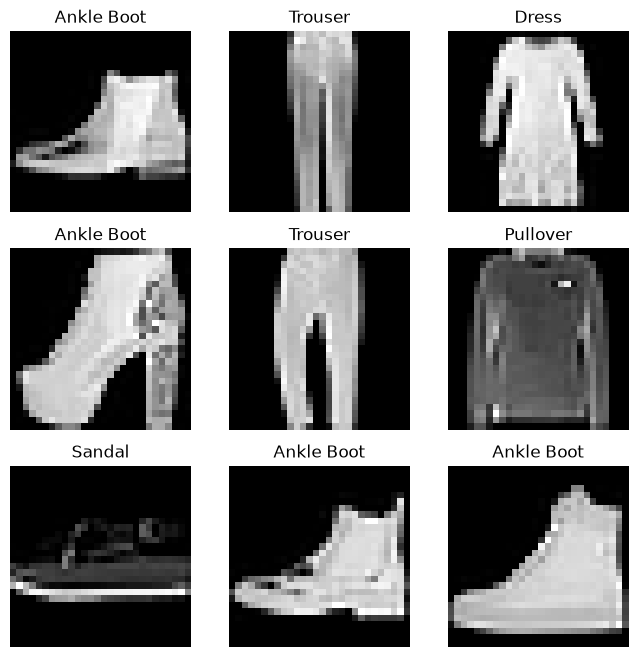

In [88]:
# here we map label numbers to their class name and print out 9 random images from the training set with their corresponding labels
labels_map = {
    0: "T-Shirt",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle Boot",
}
figure = plt.figure(figsize=(8, 8))
cols, rows = 3, 3
for i in range(1, cols * rows + 1):
    sample_idx = torch.randint(len(training_data), size=(1,)).item()
    img, label = training_data[sample_idx]
    figure.add_subplot(rows, cols, i)
    plt.title(labels_map[label])
    plt.axis("off")
    plt.imshow(img.squeeze(), cmap="gray")
plt.show()

**Creating a custom dataset for files**



In [89]:
# Below, we create a custom dataset class (inherits from Dataset) where images are located at the img_dir directory and labels in an annotations file

import os
import pandas as pd
from torchvision.io import decode_image

class CustomImageDataset(Dataset):
    # this is run when instantiating the object. Initialize image dir, annotations file, and transforms
    def __init__(self, annotations_file, img_dir, transform=None, target_transform=None):
        self.img_labels = pd.read_csv(annotations_file)
        self.img_dir = img_dir
        self.transform = transform
        self.target_transform = target_transform

    # returns # of samples of dataset
    def __len__(self):
        return len(self.img_labels)

    # loads and returns a sample from dataset at  given index
    def __getitem__(self, idx):
        img_path = os.path.join(self.img_dir, self.img_labels.iloc[idx, 0])
        image = decode_image(img_path)
        label = self.img_labels.iloc[idx, 1]
        if self.transform:
            image = self.transform(image)
        if self.target_transform:
            label = self.target_transform(label)
        return image, label

In [90]:
# from torch.utils.data import DataLoader

# train_dataloader = DataLoader(training_data, batch_size=64, shuffle=True)
# test_dataloader = DataLoader(test_data, batch_size=64, shuffle=True)
# Note: this is commented out since its a duplicate code cell

Feature batch shape: torch.Size([64, 1, 28, 28])
Labels batch shape: torch.Size([64])


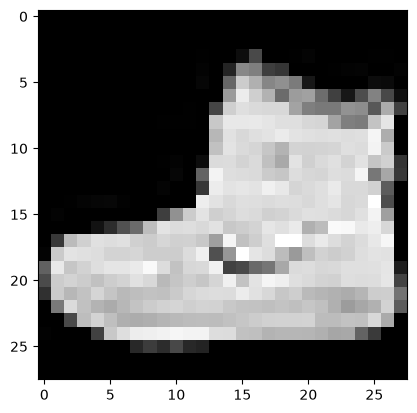

Label: 9


In [91]:
# iterate through dataloader and print out first image/label pair (9 in this case = ankle boot)
# Display image and label.
train_features, train_labels = next(iter(train_dataloader))
print(f"Feature batch shape: {train_features.size()}")
print(f"Labels batch shape: {train_labels.size()}")
img = train_features[0].squeeze()
label = train_labels[0]
plt.imshow(img, cmap="gray")
plt.show()
print(f"Label: {label}")

### Transforms

In [92]:
# Here we load the FashionMNIST dataset as before but add some more transformations
# to the images, we do as we did before and convert images to normalized tensors (from PIL) with ToImage() and ToDtype()
# to the labels, we apply one-hot encoding

import torch.nn.functional as F

ds = datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)]),
    target_transform=v2.Lambda(
        lambda y: F.one_hot(torch.tensor(y), num_classes=10).float() # here we turn int label -> size 10 one-hot encoded tensor and cast to float
    ),
)

### Build Neural Network

In [93]:
# checks if we are using an accelerator like CUDA and if so, applies it else we use CPU
device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
print(f"Using {device} device")

Using cpu device


In [94]:
# we define the same Neural Net as we did above with 3 linear layers and 2 RELU activations
class NeuralNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(28*28, 512),
            nn.ReLU(),
            nn.Linear(512, 512),
            nn.ReLU(),
            nn.Linear(512, 10),
        )

    def forward(self, x):
        x = self.flatten(x)
        logits = self.linear_relu_stack(x)
        return logits

In [95]:
# instatiate the Neural net class and move it to device
model = NeuralNetwork().to(device)
print(model)

NeuralNetwork(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (linear_relu_stack): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=10, bias=True)
  )
)


In [96]:
# here we make use of the model on a random input by passing it into model() and applying the softmax function to get probabilities from the 10 logits
# we then select the label and print it out 
X = torch.rand(1, 28, 28, device=device)
logits = model(X)
pred_probab = nn.Softmax(dim=1)(logits)
y_pred = pred_probab.argmax(1)
print(f"Predicted class: {y_pred}")

Predicted class: tensor([5])


**Model Layers**

In [97]:
# create sample minimatch of 3 images (28x28)
input_image = torch.rand(3,28,28)
print(input_image.size())

torch.Size([3, 28, 28])


In [98]:
# initialize nn.Flatten layer to covert (28x28) -> 784 dim array and we have 3 images so the output dim is 3 x 784
flatten = nn.Flatten()
flat_image = flatten(input_image)
print(flat_image.size())

torch.Size([3, 784])


In [99]:
# linear layer appleis a linear transformation using weights and biases. Here we project from the input dimension to 20

layer1 = nn.Linear(in_features=28*28, out_features=20)
hidden1 = layer1(flat_image)
print(hidden1.size())

torch.Size([3, 20])


In [100]:
# we use nn.ReLU as our activation function to introduce non-linearity
print(f"Before ReLU: {hidden1}\n\n")
hidden1 = nn.ReLU()(hidden1)
print(f"After ReLU: {hidden1}")

Before ReLU: tensor([[ 0.2222, -0.3141, -0.1624,  0.2962,  0.2392,  0.0369, -0.0215,  0.9352,
          0.5793, -0.2541, -0.5775,  0.0809, -0.0565, -0.0706,  0.0345, -0.2422,
          0.1904, -0.7302, -0.0710,  0.2296],
        [ 0.4004,  0.0503, -0.2619,  0.3862,  0.0154,  0.3407,  0.0672,  0.5027,
          0.3424, -0.0828, -0.3771,  0.0877, -0.0769,  0.0399, -0.0968, -0.2159,
          0.0073, -0.5184, -0.2516,  0.3994],
        [ 0.2979, -0.4350, -0.0144,  0.0652, -0.0039, -0.1918, -0.3964,  0.5785,
          0.3674, -0.1923, -0.5905,  0.3529,  0.3541, -0.2212, -0.2075, -0.3935,
         -0.2237, -0.4127, -0.2288,  0.2986]], grad_fn=<AddmmBackward0>)


After ReLU: tensor([[0.2222, 0.0000, 0.0000, 0.2962, 0.2392, 0.0369, 0.0000, 0.9352, 0.5793,
         0.0000, 0.0000, 0.0809, 0.0000, 0.0000, 0.0345, 0.0000, 0.1904, 0.0000,
         0.0000, 0.2296],
        [0.4004, 0.0503, 0.0000, 0.3862, 0.0154, 0.3407, 0.0672, 0.5027, 0.3424,
         0.0000, 0.0000, 0.0877, 0.0000, 0.0399, 0.00

In [101]:
# here nn.Sequential is an ordered container of nn modules. We can just throw in all of our NN layers into one object and pass our input through it

seq_modules = nn.Sequential(
    flatten,
    layer1,
    nn.ReLU(),
    nn.Linear(20, 10)
)
input_image = torch.rand(3,28,28)
logits = seq_modules(input_image)

In [102]:
# we pass the raw values from seq_modules to softmax to scale them between [0, 1]. Dim = 1 means we want the values to sum to 1 along columns
softmax = nn.Softmax(dim=1)
pred_probab = softmax(logits)

In [103]:
# here we can see all of the parameters that are tracked by our NN, specifically the weights and biases for each of the 3 linear layers (RELU doesn't have weights)
print(f"Model structure: {model}\n\n")

for name, param in model.named_parameters():
    print(f"Layer: {name} | Size: {param.size()} | Values : {param[:2]} \n")

Model structure: NeuralNetwork(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (linear_relu_stack): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=10, bias=True)
  )
)


Layer: linear_relu_stack.0.weight | Size: torch.Size([512, 784]) | Values : tensor([[ 0.0343,  0.0323, -0.0191,  ...,  0.0056,  0.0310,  0.0220],
        [-0.0351,  0.0191,  0.0297,  ...,  0.0229,  0.0303,  0.0263]],
       grad_fn=<SliceBackward0>) 

Layer: linear_relu_stack.0.bias | Size: torch.Size([512]) | Values : tensor([0.0323, 0.0303], grad_fn=<SliceBackward0>) 

Layer: linear_relu_stack.2.weight | Size: torch.Size([512, 512]) | Values : tensor([[-0.0051,  0.0164, -0.0215,  ...,  0.0049,  0.0299,  0.0358],
        [-0.0232, -0.0330, -0.0399,  ...,  0.0011,  0.0272,  0.0379]],
       grad_fn=<SliceBackward0>) 

Layer: linear_relu_stack.2.bias | Si

### Automatic Differentiation with torch.autograd

In [104]:
# to demonstrate how pytorch computes gradients with backprop, we define a simple neural net with 1 hidden layer
x = torch.ones(5)  # input tensor
y = torch.zeros(3)  # expected output
w = torch.randn(5, 3, requires_grad=True)
b = torch.randn(3, requires_grad=True)
z = torch.matmul(x, w)+b
loss = torch.nn.functional.binary_cross_entropy_with_logits(z, y)

In [105]:
# Here we can see that each term (loss and z) have a grad_fn properety which is a reference to the back prop function
print(f"Gradient function for z = {z.grad_fn}")
print(f"Gradient function for loss = {loss.grad_fn}")

Gradient function for z = <AddBackward0 object at 0x71d8bc1b4f10>
Gradient function for loss = <BinaryCrossEntropyWithLogitsBackward0 object at 0x71d8bc146b90>


In [106]:
# loss.backward() computes the derivatives of loss w.r.t params and then we fetch them from w.grad and b.grad. Note we call backward on the root (loss) so it can use chain rule
loss.backward()
print(w.grad)
print(b.grad)

tensor([[0.1843, 0.2724, 0.0062],
        [0.1843, 0.2724, 0.0062],
        [0.1843, 0.2724, 0.0062],
        [0.1843, 0.2724, 0.0062],
        [0.1843, 0.2724, 0.0062]])
tensor([0.1843, 0.2724, 0.0062])


In [107]:
# here we can disable gradient tracking with the torch.no_grad() block (useful for when we want to just make predictions)
z = torch.matmul(x, w)+b
print(z.requires_grad)

with torch.no_grad():
    z = torch.matmul(x, w)+b
print(z.requires_grad)

True
False


In [108]:
# alternatively, we can use the detach method on the tensor
z = torch.matmul(x, w)+b
z_det = z.detach()
print(z_det.requires_grad)

False


In [109]:
# when our output is a tensor rather than scalar, we can compute the Jacobian product (rather than jacobian matrix) by doing v^T * J where v is the output tensor
# We accomplish this by calling backward() as we did above on our output and pass in the input vector "v" which is just an arbitrary tensor of ones in this case
inp = torch.eye(4, 5, requires_grad=True)
out = (inp+1).pow(2).t()
out.backward(torch.ones_like(out), retain_graph=True)
print(f"First call\n{inp.grad}")
out.backward(torch.ones_like(out), retain_graph=True)
print(f"\nSecond call\n{inp.grad}")
inp.grad.zero_()
out.backward(torch.ones_like(out), retain_graph=True)
print(f"\nCall after zeroing gradients\n{inp.grad}")

First call
tensor([[4., 2., 2., 2., 2.],
        [2., 4., 2., 2., 2.],
        [2., 2., 4., 2., 2.],
        [2., 2., 2., 4., 2.]])

Second call
tensor([[8., 4., 4., 4., 4.],
        [4., 8., 4., 4., 4.],
        [4., 4., 8., 4., 4.],
        [4., 4., 4., 8., 4.]])

Call after zeroing gradients
tensor([[4., 2., 2., 2., 2.],
        [2., 4., 2., 2., 2.],
        [2., 2., 4., 2., 2.],
        [2., 2., 2., 4., 2.]])


### Optimizing Model Params

In [110]:
# we've already defined the dataset and neural network above (we will use "model" object)

# here we define the learning rate, batch size, and # of epochs
learning_rate = 1e-3
batch_size = 64
epochs = 5

In [111]:
# Initialize the loss function
loss_fn = nn.CrossEntropyLoss()

# initialize optimizer and pass in model's parameters to be trained and learning rate
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)

In [112]:
# here we define the train and testing loop very similar to the quickstart notebook (at very top)
# logic: set model to train -> iterate through batches -> for each batch, compute prediction and loss then update weights based on gradients -> finish once we've done full pass through the data
# the test loop works very similarly except we are in eval mode and not calculating any gradients

def train_loop(dataloader, model, loss_fn, optimizer):
    size = len(dataloader.dataset)
    # Set the model to training mode - important for batch normalization and dropout layers
    # Unnecessary in this situation but added for best practices
    model.train()
    total_loss = 0.0
    total_samples = 0
    
    for batch, (X, y) in enumerate(dataloader):
        # Compute prediction and loss
        pred = model(X)
        loss = loss_fn(pred, y)
        total_loss += loss.item() * X.size(0) # track total loss
        total_samples += X.size(0) # track # of samples

        # Backpropagation
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()

        if batch % 100 == 0:
            loss, current = loss.item(), batch * batch_size + len(X)
            print(f"loss: {loss:>7f}  [{current:>5d}/{size:>5d}]")

    # Return the average loss across all samples seen in this epoch.
    return total_loss / total_samples


def test_loop(dataloader, model, loss_fn):
    # Set the model to evaluation mode - important for batch normalization and dropout layers
    # Unnecessary in this situation but added for best practices
    model.eval()
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    test_loss, correct = 0, 0

    # Evaluating the model with torch.no_grad() ensures that no gradients are computed during test mode
    # also serves to reduce unnecessary gradient computations and memory usage for tensors with requires_grad=True
    with torch.no_grad():
        for X, y in dataloader:
            pred = model(X)
            test_loss += loss_fn(pred, y).item()
            correct += (pred.argmax(1) == y).type(torch.float).sum().item()

    test_loss /= num_batches
    correct /= size
    print(f"Test Error: \n Accuracy: {(100*correct):>0.1f}%, Avg loss: {test_loss:>8f} \n")

Epoch 1
-------------------------------
loss: 2.297779  [   64/60000]
loss: 2.286296  [ 6464/60000]
loss: 2.260983  [12864/60000]
loss: 2.258727  [19264/60000]
loss: 2.246893  [25664/60000]
loss: 2.204457  [32064/60000]
loss: 2.213639  [38464/60000]
loss: 2.171957  [44864/60000]
loss: 2.174036  [51264/60000]
loss: 2.144772  [57664/60000]
Average training loss: 2.221144
Test Error: 
 Accuracy: 44.9%, Avg loss: 2.132925 

Epoch 2
-------------------------------
loss: 2.137616  [   64/60000]
loss: 2.133166  [ 6464/60000]
loss: 2.067703  [12864/60000]
loss: 2.093492  [19264/60000]
loss: 2.037044  [25664/60000]
loss: 1.965256  [32064/60000]
loss: 2.001319  [38464/60000]
loss: 1.911494  [44864/60000]
loss: 1.932748  [51264/60000]
loss: 1.854086  [57664/60000]
Average training loss: 2.003800
Test Error: 
 Accuracy: 53.4%, Avg loss: 1.850159 

Epoch 3
-------------------------------
loss: 1.880312  [   64/60000]
loss: 1.853994  [ 6464/60000]
loss: 1.735228  [12864/60000]
loss: 1.783609  [19264

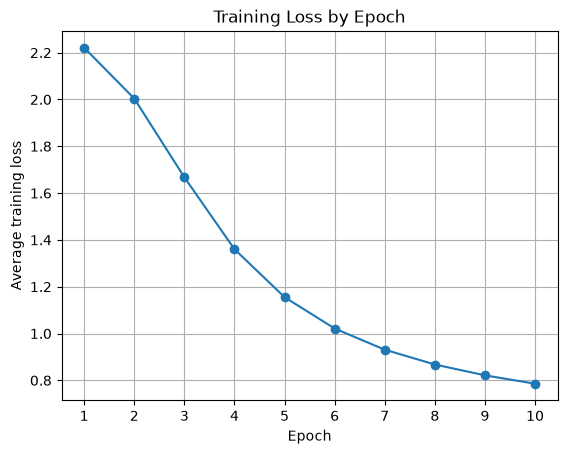

In [113]:
# code to train the model for 10 epochs and measure the test set performance after each epoch

epochs = 10
loss_history = []
for t in range(epochs):
    print(f"Epoch {t+1}\n-------------------------------")
    epoch_loss = train_loop(train_dataloader, model, loss_fn, optimizer)
    loss_history.append(epoch_loss)
    print(f"Average training loss: {epoch_loss:.6f}")
    test_loop(test_dataloader, model, loss_fn)
print("Done!")

# plot loss history
plt.plot(range(1, epochs + 1), loss_history, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Average training loss")
plt.title("Training Loss by Epoch")
plt.xticks(range(1, epochs + 1))
plt.grid(True)
plt.show()

In [114]:
# We can also create another neural network, this time with three hidden layers (512 neurons each) and we can then compare our performance

class NeuralNet3(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(28*28, 512),
            nn.ReLU(),
            nn.Linear(512, 512),
            nn.ReLU(),
            nn.Linear(512, 512), # adding third hidden layer here!
            nn.ReLU(),
            nn.Linear(512, 10)   
        )

    def forward(self, x):
        x = self.flatten(x)
        logits = self.linear_relu_stack(x)
        return logits

model_new = NeuralNet3()



In [116]:
# initialize loss function and optimizer
loss_fn = nn.CrossEntropyLoss()

# initialize optimizer and pass in model's parameters to be trained and learning rate
optimizer = torch.optim.SGD(model_new.parameters(), lr=learning_rate)

Epoch 1
-------------------------------
loss: 2.302557  [   64/60000]
loss: 2.213567  [ 6464/60000]
loss: 2.140707  [12864/60000]
loss: 2.134274  [19264/60000]
loss: 2.150106  [25664/60000]
loss: 2.031271  [32064/60000]
loss: 2.085938  [38464/60000]
loss: 1.998418  [44864/60000]
loss: 2.015523  [51264/60000]
loss: 1.932703  [57664/60000]
Average training loss: 2.075894
Test Error: 
 Accuracy: 43.2%, Avg loss: 1.935221 

Epoch 2
-------------------------------
loss: 1.987524  [   64/60000]
loss: 1.938566  [ 6464/60000]
loss: 1.830748  [12864/60000]
loss: 1.844632  [19264/60000]
loss: 1.788469  [25664/60000]
loss: 1.721543  [32064/60000]
loss: 1.750668  [38464/60000]
loss: 1.653642  [44864/60000]
loss: 1.685161  [51264/60000]
loss: 1.578147  [57664/60000]
Average training loss: 1.760868
Test Error: 
 Accuracy: 46.8%, Avg loss: 1.597004 

Epoch 3
-------------------------------
loss: 1.681209  [   64/60000]
loss: 1.627742  [ 6464/60000]
loss: 1.495822  [12864/60000]
loss: 1.526363  [19264

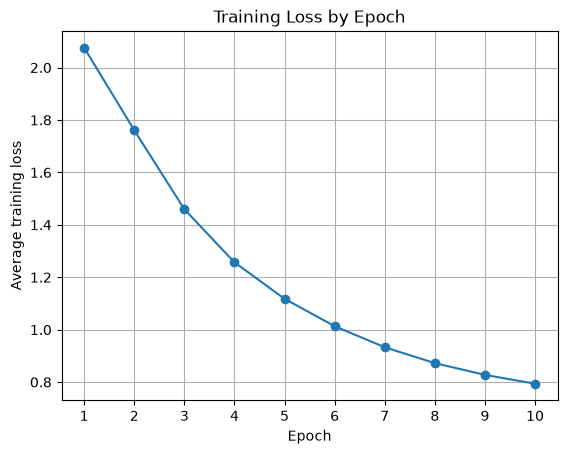

In [117]:
# apply same code as above to train this model for 10 epochs, compare accuracy and loss graph
epochs = 10
loss_history = []
for t in range(epochs):
    print(f"Epoch {t+1}\n-------------------------------")
    epoch_loss = train_loop(train_dataloader, model_new, loss_fn, optimizer)
    loss_history.append(epoch_loss)
    print(f"Average training loss: {epoch_loss:.6f}")
    test_loop(test_dataloader, model_new, loss_fn)
print("Done!")

# plot loss history
plt.plot(range(1, epochs + 1), loss_history, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Average training loss")
plt.title("Training Loss by Epoch")
plt.xticks(range(1, epochs + 1))
plt.grid(True)
plt.show()

Results:

Creating a neural network with 3 hidden layers (linear with 512 neurons each) didn't really have too much of an impact on our overall accuracy and loss (stayed mostly the same) since we've just added one more hidden layer to the original NeuralNetwork class. Their loss curves look quite similar with the new one having it be slightly more smooth and gradual. This is overall expected since we didn't change the architecture much.

### Save and Load Model



In [55]:
# here we load a pre-trained model "vgg16" used for image classification via the torchvision.models module
# we can save the learned params as a file locally through the state_dict() attribute

import torchvision.models as models

model = models.vgg16(weights='IMAGENET1K_V1')
torch.save(model.state_dict(), 'model_weights.pth')

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /home/aadibery/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:20<00:00, 27.5MB/s] 


In [56]:
# as we did in the quickstart notebook, we can also create an insance of the model (no trained weights)
# then we can load the state dictionary (weights only) into the model
model = models.vgg16() # we do not specify ``weights``, i.e. create untrained model
model.load_state_dict(torch.load('model_weights.pth', weights_only=True))
model.eval()

VGG(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU(inplace=True)
    (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU(inplace=True)
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU(inplace=True)
    (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (15): ReLU(inplace=True)
    (16): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1

In [ ]:
# when we also want to save the class structure (NN structure) with the model weights, we can do this and pass model rather than state_dict()
torch.save(model, 'model.pth')

In [ ]:
# then we can load the model in this fashion, specifying weights_only=False
model = torch.load('model.pth', weights_only=False)